# Clinical Recovery Analytics Platform — reproducible walkthrough

This notebook ties the whole project together on the **synthetic** dataset:
it loads the data, runs the key **SQL** analytics with DuckDB, visualises the
**clinical & operational KPIs**, and trains the two **predictive models**.
Every result and chart below is *executed output*.

See the full write-up in [`/docs`](../docs) and the model details in
[`/ml`](../ml). No real patient data is used.

In [1]:
%matplotlib inline
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
import duckdb, pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.width", 120); pd.set_option("display.max_columns", 20)

HERE = pathlib.Path.cwd()
REPO = HERE.parent if HERE.name == "notebooks" else HERE
DATA = REPO / "data"
print("Project root:", REPO.name)

con = duckdb.connect()
con.execute("""CREATE MACRO to_char(d, f) AS
    CASE f WHEN 'YYYY-MM' THEN strftime(d,'%Y-%m') ELSE strftime(d,'%Y-%m-%d') END""")
for t in ["clinics","practitioners","patients","conditions","care_plans",
          "appointments","encounters","observations"]:
    con.execute(f"CREATE TABLE {t} AS SELECT * FROM read_csv_auto('{DATA}/{t}.csv', header=true)")
print("Loaded 8 tables from the FHIR-derived CSVs.")

Project root: linical Recovery Analytics Platform using FHIR, SQL and Power BI


Loaded 8 tables from the FHIR-derived CSVs.


## 1. The dataset

In [2]:
con.execute("""
SELECT 'patients' AS table, COUNT(*) AS rows FROM patients
UNION ALL SELECT 'episodes (care plans)', COUNT(*) FROM care_plans
UNION ALL SELECT 'appointments', COUNT(*) FROM appointments
UNION ALL SELECT 'encounters', COUNT(*) FROM encounters
UNION ALL SELECT 'observations (PROMs)', COUNT(*) FROM observations""").df()

,table,rows
0,patients,4500
1,episodes (care plans),5467
2,appointments,64213
3,encounters,51415
4,observations (PROMs),20790


## 2. Operational — where is capacity lost?

No-show and cancellation rates are computed over **resolved** appointments
(`fulfilled + noshow + cancelled`).

In [3]:
con.execute("""
SELECT c.name AS clinic,
  ROUND(100.0*SUM(CASE WHEN a.status='noshow' THEN 1 ELSE 0 END)
        /NULLIF(SUM(CASE WHEN a.status IN ('fulfilled','noshow','cancelled') THEN 1 ELSE 0 END),0),1) AS noshow_pct,
  ROUND(100.0*SUM(CASE WHEN a.status='cancelled' THEN 1 ELSE 0 END)
        /NULLIF(SUM(CASE WHEN a.status IN ('fulfilled','noshow','cancelled') THEN 1 ELSE 0 END),0),1) AS cancel_pct
FROM appointments a JOIN clinics c USING(clinic_id)
GROUP BY 1 ORDER BY noshow_pct DESC""").df()

,clinic,noshow_pct,cancel_pct
0,ARN Sevilla,14.9,8.2
1,ARN Barcelona Sants,13.8,7.7
2,ARN Malaga,12.4,7.3
3,ARN Madrid Norte,11.8,6.7
4,ARN Valencia,10.9,6.6
5,ARN Bilbao,9.8,5.9
6,ARN Madrid Centro,8.6,5.9
7,ARN Barcelona Eixample,8.1,4.9


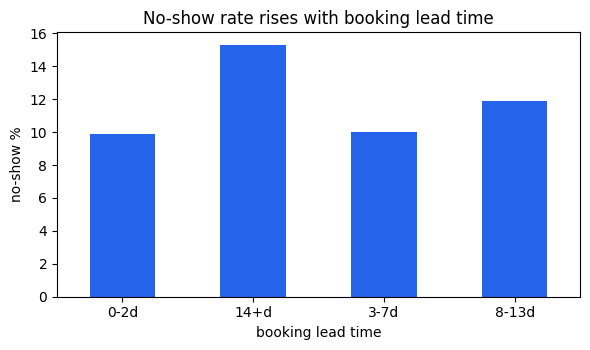

,lead_band,noshow_pct
0,0-2d,9.9
1,14+d,15.3
2,3-7d,10.0
3,8-13d,11.9


In [4]:
lt = con.execute("""
SELECT CASE WHEN lead_time_days<=2 THEN '0-2d' WHEN lead_time_days<=7 THEN '3-7d'
            WHEN lead_time_days<=13 THEN '8-13d' ELSE '14+d' END AS lead_band,
       ROUND(100.0*AVG(CASE WHEN status='noshow' THEN 1 ELSE 0 END),1) AS noshow_pct
FROM appointments WHERE status IN ('fulfilled','noshow','cancelled')
GROUP BY 1 ORDER BY 1""").df()
ax = lt.plot.bar(x='lead_band', y='noshow_pct', legend=False, color='#2563eb', figsize=(6,3.6))
ax.set_xlabel('booking lead time'); ax.set_ylabel('no-show %')
ax.set_title('No-show rate rises with booking lead time')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
lt

## 3. Clinical outcomes (PROMs + MCID)

Recovery is reported as **% of episodes reaching the Minimal Clinically Important
Difference (MCID)** on the functional instrument, harmonised across conditions.

In [5]:
con.execute("""
SELECT display AS diagnosis, COUNT(*) AS episodes,
       ROUND(100.0*COUNT(*)/SUM(COUNT(*)) OVER(),1) AS pct_of_total
FROM conditions GROUP BY 1 ORDER BY 2 DESC LIMIT 6""").df()

,diagnosis,episodes,pct_of_total
0,"Low back pain, non-specific",1090,19.9
1,Rotator cuff / shoulder impingement,655,12.0
2,Cervicalgia (neck pain),650,11.9
3,Knee osteoarthritis,570,10.4
4,Lumbar radiculopathy (sciatica),428,7.8
5,Lateral ankle sprain,372,6.8


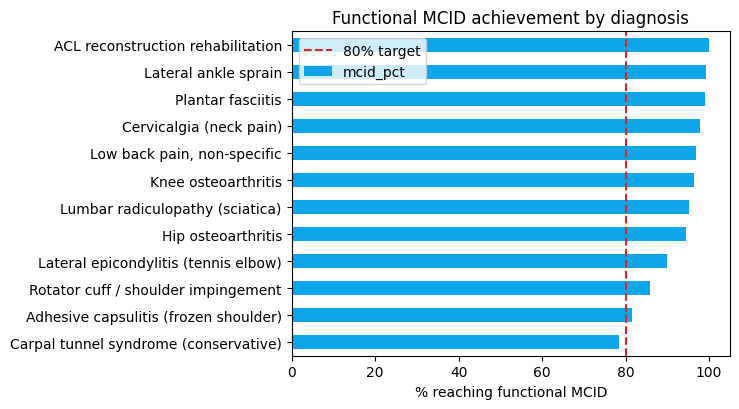

,diagnosis,mcid_pct
0,Carpal tunnel syndrome (conservative),78.3
1,Adhesive capsulitis (frozen shoulder),81.6
2,Rotator cuff / shoulder impingement,85.9
3,Lateral epicondylitis (tennis elbow),89.9
4,Hip osteoarthritis,94.4
5,Lumbar radiculopathy (sciatica),95.3
6,Knee osteoarthritis,96.3
7,"Low back pain, non-specific",96.8
8,Cervicalgia (neck pain),97.9
9,Plantar fasciitis,99.0


In [6]:
fo = con.execute("""
WITH p AS (
  SELECT care_plan_id,
    MAX(instrument) FILTER (WHERE instrument<>'NPRS') AS fi,
    MAX(value_numeric) FILTER (WHERE instrument<>'NPRS' AND measure_point='baseline')  AS fb,
    MAX(value_numeric) FILTER (WHERE instrument<>'NPRS' AND measure_point='discharge') AS fd
  FROM observations GROUP BY 1)
SELECT cn.display AS diagnosis,
  ROUND(100.0*AVG(CASE WHEN p.fd IS NULL THEN NULL
       WHEN (CASE WHEN p.fi='LEFS' THEN p.fd-p.fb ELSE p.fb-p.fd END)
            >= (CASE p.fi WHEN 'ODI' THEN 10 WHEN 'NDI' THEN 7
                          WHEN 'QuickDASH' THEN 15 WHEN 'LEFS' THEN 9 END)
       THEN 1 ELSE 0 END),1) AS mcid_pct
FROM care_plans cp JOIN conditions cn USING(condition_id) JOIN p USING(care_plan_id)
GROUP BY 1 HAVING COUNT(*) FILTER (WHERE p.fd IS NOT NULL) > 50
ORDER BY mcid_pct""").df()
ax = fo.plot.barh(x='diagnosis', y='mcid_pct', legend=False, color='#0ea5e9', figsize=(7.5,4.2))
ax.axvline(80, ls='--', color='#dc2626', label='80% target'); ax.set_xlabel('% reaching functional MCID')
ax.set_ylabel(''); ax.set_title('Functional MCID achievement by diagnosis'); ax.legend()
plt.tight_layout(); plt.show()
fo

### Does adherence drive recovery?

In [7]:
con.execute("""
WITH p AS (
  SELECT care_plan_id, MAX(instrument) FILTER (WHERE instrument<>'NPRS') AS fi,
    MAX(value_numeric) FILTER (WHERE instrument<>'NPRS' AND measure_point='baseline')  AS fb,
    MAX(value_numeric) FILTER (WHERE instrument<>'NPRS' AND measure_point='discharge') AS fd
  FROM observations GROUP BY 1)
SELECT CASE WHEN LEAST(cp.attended_sessions*1.0/cp.planned_sessions,1)<0.7 THEN '1 <70%'
            WHEN LEAST(cp.attended_sessions*1.0/cp.planned_sessions,1)<0.9 THEN '2 70-89%'
            ELSE '3 90-100%' END AS adherence_band,
       COUNT(*) AS episodes,
       ROUND(AVG(CASE WHEN p.fi='LEFS' THEN p.fd-p.fb ELSE p.fb-p.fd END),1) AS mean_improvement
FROM care_plans cp JOIN p USING(care_plan_id)
WHERE p.fd IS NOT NULL GROUP BY 1 ORDER BY 1""").df()

,adherence_band,episodes,mean_improvement
0,1 <70%,12,18.9
1,2 70-89%,125,22.3
2,3 90-100%,3319,24.5


## 4. Drop-out risk register (operational SQL)

Active episodes with a growing attendance gap and sessions still to do.

In [8]:
con.execute("""
WITH ev AS (SELECT care_plan_id, MAX(period_start::date) AS last_visit
            FROM encounters WHERE status='finished' GROUP BY 1)
SELECT CASE WHEN (DATE '2026-06-14'-last_visit)>=28 THEN 'High'
            WHEN (DATE '2026-06-14'-last_visit)>=14 THEN 'Medium' ELSE 'Low' END AS dropout_risk,
       COUNT(*) AS episodes,
       SUM(cp.planned_sessions-cp.attended_sessions) AS sessions_at_risk
FROM care_plans cp JOIN ev USING(care_plan_id)
WHERE cp.status='active' AND cp.attended_sessions<cp.planned_sessions
GROUP BY 1 ORDER BY 1""").df()

,dropout_risk,episodes,sessions_at_risk
0,High,67,743.0
1,Low,720,6364.0
2,Medium,115,861.0


## 5. Predictive models

Leakage-safe features (`ml/features.py`), time-based train/test split. We use
gradient boosting for no-show and an interpretable logistic model for early
drop-out (the better performer there).

In [9]:
sys.path.insert(0, str(REPO/'ml'))
import features as F
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve

data = F.load_data(str(DATA))

def run(kind):
    if kind == 'noshow':
        X,y,meta,num,cat = F.build_noshow_features(data)
        cutoff, datecol = pd.Timestamp('2026-01-01'), 'scheduled_date'
        pre = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat)],
                                remainder='passthrough')
        clf = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.08, random_state=42)
    else:
        X,y,meta,num,cat = F.build_dropout_features(data)
        cutoff, datecol = pd.Timestamp('2025-10-01'), 'period_start'
        pre = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat),
                                 ('num', StandardScaler(), num)])
        clf = LogisticRegression(max_iter=1000)
    tr = meta[datecol] < cutoff; te = ~tr
    pipe = Pipeline([('pre', pre), ('clf', clf)]).fit(X[tr], y[tr])
    return y[te].values, pipe.predict_proba(X[te])[:,1]

yns,pns = run('noshow'); ydo,pdo = run('dropout')
print('No-show   AUROC %.3f | AUPRC %.3f (base %.3f)' % (roc_auc_score(yns,pns), average_precision_score(yns,pns), yns.mean()))
print('Drop-out  AUROC %.3f | AUPRC %.3f (base %.3f)' % (roc_auc_score(ydo,pdo), average_precision_score(ydo,pdo), ydo.mean()))

No-show   AUROC 0.585 | AUPRC 0.156 (base 0.123)
Drop-out  AUROC 0.657 | AUPRC 0.468 (base 0.264)


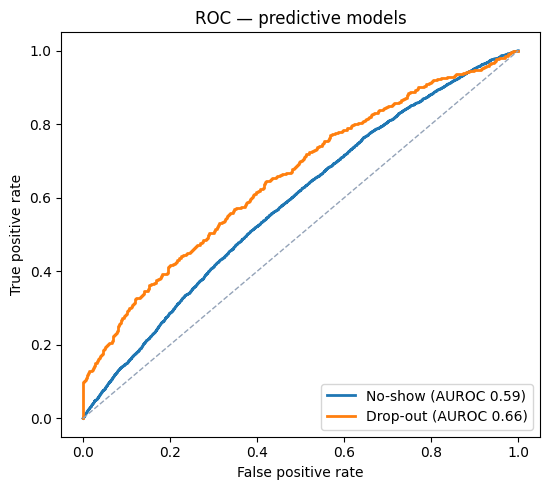

In [10]:
fig, ax = plt.subplots(figsize=(5.6,5))
for y_, p_, lab in [(yns,pns,'No-show'), (ydo,pdo,'Drop-out')]:
    fpr,tpr,_ = roc_curve(y_,p_)
    ax.plot(fpr,tpr,lw=2,label=f'{lab} (AUROC {roc_auc_score(y_,p_):.2f})')
ax.plot([0,1],[0,1],'--',color='#94a3b8',lw=1)
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
ax.set_title('ROC — predictive models'); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

## 6. Takeaways

- ~**18% of capacity** is lost to no-shows/cancellations, and the risk
  concentrates by **booking lead time** and **clinic** — targetable with
  reminders and overbooking.
- Recovery is strong overall but **uneven by condition**, and **rises with
  adherence** — which is why the **drop-out risk register** and the
  **early-warning model** matter.
- The models are **decision support** (calibrated risk scores feeding the
  register), governed under GDPR and the EU AI Act — see [`docs/07_ai_future.md`](../docs/07_ai_future.md).

*Synthetic data; figures are reproducible (`seed = 42`).*